# AI-Powered Sports Analytics & Performance Platform

This project uses Artificial Intelligence and Machine Learning
for sports player analysis, activity recognition, performance
prediction, match outcome prediction, and future performance forecasting.

## Submodules

1. Player Detection — CNN
2. Player Activity Recognition — CNN
3. Player Performance Prediction — ANN
4. Match Outcome Prediction — ANN
5. Player Performance Forecasting — LSTM

# 🏆 AI-Powered Sports Analytics & Performance Platform

### An Artificial Intelligence based system for:
- Player Detection
- Player Activity Recognition
- Player Performance Prediction
- Match Outcome Prediction
- Player Performance Forecasting

---

## Technologies Used

- Python
- Jupyter Notebook
- TensorFlow / Keras
- CNN
- ANN
- LSTM
- NumPy
- Pandas
- Matplotlib
- Scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, LSTM

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, accuracy_score

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nProject Contents:")
print(os.listdir())

Current Working Directory:
C:\Users\ASUS\AI_Sport_Analytics

Project Contents:
['.ipynb_checkpoints', 'AI_Sport_Analytics.ipynb', 'Datasets', 'Image', 'Models']


In [3]:
np.random.seed(42)

player_data = pd.DataFrame({
    "player_id": range(1, 101),
    "age": np.random.randint(18, 35, 100),
    "speed": np.random.randint(20, 36, 100),
    "goals": np.random.randint(0, 10, 100),
    "assists": np.random.randint(0, 10, 100),
    "pass_accuracy": np.random.randint(60, 101, 100),
    "stamina": np.random.randint(60, 101, 100),
    "shots": np.random.randint(1, 15, 100),
    "tackles": np.random.randint(0, 12, 100)
})

player_data.head()

,player_id,age,speed,goals,assists,pass_accuracy,stamina,shots,tackles
0,1,24,29,0,7,65,66,2,4
1,2,32,26,4,7,91,63,12,6
2,3,28,34,0,6,89,70,14,7
3,4,25,33,7,2,94,88,10,0
4,5,24,26,0,0,99,95,4,5


In [4]:
player_data.to_csv("datasets/player_data.csv", index=False)

print("player_data.csv created successfully!")

player_data.csv created successfully!


In [5]:
print(os.listdir("datasets"))

['player_data.csv']


In [6]:
performance_data = pd.DataFrame({
    "player_id": range(1, 101),
    "speed": np.random.randint(20, 36, 100),
    "goals": np.random.randint(0, 10, 100),
    "assists": np.random.randint(0, 10, 100),
    "pass_accuracy": np.random.randint(60, 101, 100),
    "stamina": np.random.randint(60, 101, 100),
    "shots": np.random.randint(1, 15, 100),
    "tackles": np.random.randint(0, 12, 100)
})

performance_data["performance_score"] = (
    performance_data["speed"] * 1.2 +
    performance_data["goals"] * 5 +
    performance_data["assists"] * 4 +
    performance_data["pass_accuracy"] * 0.3 +
    performance_data["stamina"] * 0.2 +
    performance_data["shots"] * 1.5 +
    performance_data["tackles"] * 1.2
)

performance_data.head()

,player_id,speed,goals,assists,pass_accuracy,stamina,shots,tackles,performance_score
0,1,20,7,9,95,60,2,4,143.3
1,2,31,2,4,95,73,5,11,127.0
2,3,23,6,6,85,61,10,11,147.5
3,4,27,2,9,86,87,4,2,130.0
4,5,24,6,1,64,89,9,5,119.3


In [7]:
performance_data.to_csv(
    "datasets/performance_data.csv",
    index=False
)

print("performance_data.csv created successfully!")

performance_data.csv created successfully!


In [8]:
print(os.listdir("datasets"))

['performance_data.csv', 'player_data.csv']


In [9]:
match_data = pd.DataFrame({
    "match_id": range(1, 101),
    "team_a_score": np.random.randint(0, 6, 100),
    "team_b_score": np.random.randint(0, 6, 100),
    "team_a_possession": np.random.randint(40, 61, 100),
    "team_b_possession": np.random.randint(40, 61, 100),
    "team_a_shots": np.random.randint(3, 16, 100),
    "team_b_shots": np.random.randint(3, 16, 100),
    "team_a_ranking": np.random.randint(1, 21, 100),
    "team_b_ranking": np.random.randint(1, 21, 100)
})

def get_result(row):
    if row["team_a_score"] > row["team_b_score"]:
        return 1
    elif row["team_a_score"] < row["team_b_score"]:
        return 0
    else:
        return 2

match_data["result"] = match_data.apply(get_result, axis=1)

match_data.head()

,match_id,team_a_score,team_b_score,team_a_possession,team_b_possession,team_a_shots,team_b_shots,team_a_ranking,team_b_ranking,result
0,1,3,0,56,54,6,3,16,7,1
1,2,0,1,51,45,14,10,13,17,0
2,3,3,3,56,50,14,14,9,10,2
3,4,0,1,49,52,6,10,13,10,0
4,5,1,0,40,40,14,14,9,4,1


In [10]:
match_data.to_csv(
    "datasets/match_data.csv",
    index=False
)

print("match_data.csv created successfully!")

match_data.csv created successfully!


In [11]:
print(os.listdir("datasets"))

['match_data.csv', 'performance_data.csv', 'player_data.csv']


In [12]:
player_data = pd.read_csv("datasets/player_data.csv")

print("Dataset loaded successfully!")
print("Shape:", player_data.shape)

player_data.head()

Dataset loaded successfully!
Shape: (100, 9)


,player_id,age,speed,goals,assists,pass_accuracy,stamina,shots,tackles
0,1,24,29,0,7,65,66,2,4
1,2,32,26,4,7,91,63,12,6
2,3,28,34,0,6,89,70,14,7
3,4,25,33,7,2,94,88,10,0
4,5,24,26,0,0,99,95,4,5


In [13]:
player_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   player_id      100 non-null    int64
 1   age            100 non-null    int64
 2   speed          100 non-null    int64
 3   goals          100 non-null    int64
 4   assists        100 non-null    int64
 5   pass_accuracy  100 non-null    int64
 6   stamina        100 non-null    int64
 7   shots          100 non-null    int64
 8   tackles        100 non-null    int64
dtypes: int64(9)
memory usage: 7.2 KB


In [14]:
player_data.describe()

,player_id,age,speed,goals,assists,pass_accuracy,stamina,shots,tackles
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.0000,100.000000,100.000000,100.000000
mean,50.500000,25.480000,28.300000,3.830000,4.330000,80.7600,80.800000,7.870000,4.670000
std,29.011492,4.835642,4.430154,2.835757,2.937239,11.7775,11.511084,4.076677,3.559182
min,1.000000,18.000000,20.000000,0.000000,0.000000,60.0000,60.000000,1.000000,0.000000
25%,25.750000,21.000000,25.000000,1.000000,2.000000,71.0000,71.000000,4.750000,1.000000
50%,50.500000,25.000000,29.000000,3.000000,5.000000,83.0000,80.500000,8.000000,4.000000
75%,75.250000,29.000000,32.000000,6.000000,7.000000,91.0000,91.000000,12.000000,8.000000
max,100.000000,34.000000,35.000000,9.000000,9.000000,100.0000,100.000000,14.000000,11.000000


In [15]:
player_data.isnull().sum()

player_id        0
age              0
speed            0
goals            0
assists          0
pass_accuracy    0
stamina          0
shots            0
tackles          0
dtype: int64

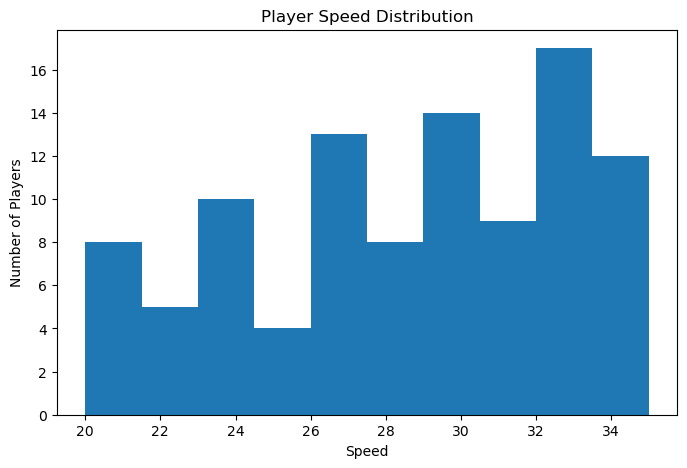

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(player_data["speed"], bins=10)

plt.title("Player Speed Distribution")
plt.xlabel("Speed")
plt.ylabel("Number of Players")

plt.show()

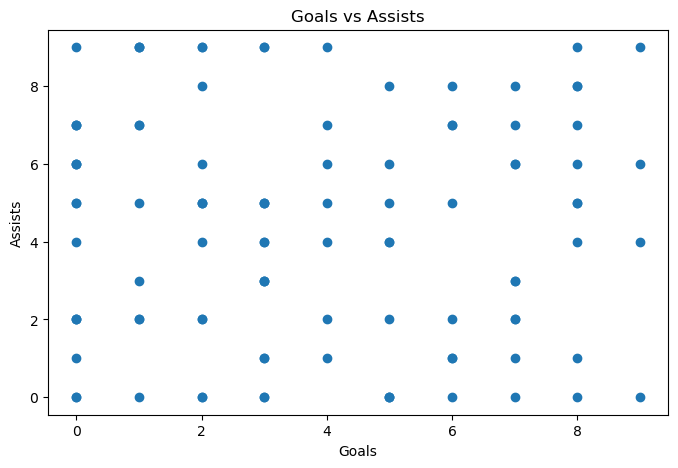

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    player_data["goals"],
    player_data["assists"]
)

plt.title("Goals vs Assists")
plt.xlabel("Goals")
plt.ylabel("Assists")

plt.show()

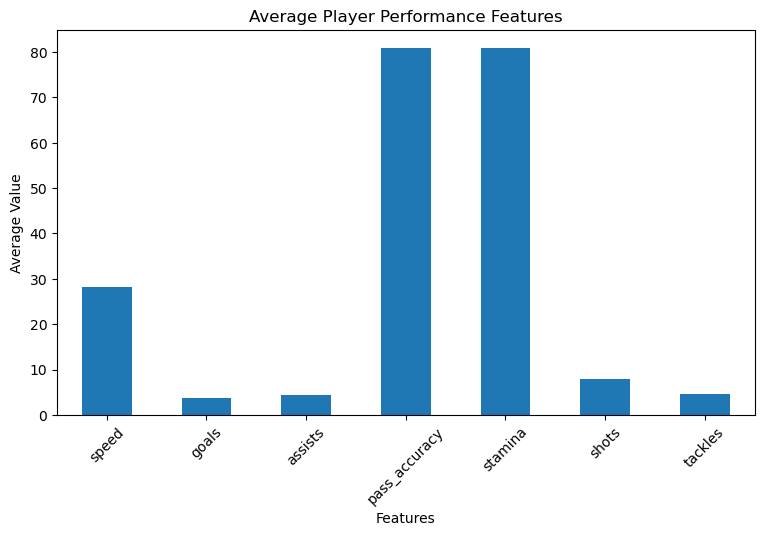

In [18]:
features = [
    "speed",
    "goals",
    "assists",
    "pass_accuracy",
    "stamina",
    "shots",
    "tackles"
]

player_data[features].mean().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Player Performance Features")
plt.xlabel("Features")
plt.ylabel("Average Value")

plt.xticks(rotation=45)
plt.show()

In [19]:
import os

os.makedirs("images/player", exist_ok=True)
os.makedirs("images/non_player", exist_ok=True)

print("Image folders created successfully!")

Image folders created successfully!


In [20]:
print(os.listdir("images"))

['non_player', 'player']


In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [22]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    "images",
    target_size=(128, 128),
    batch_size=4,
    class_mode="binary",
    subset="training"
)

validation_data = datagen.flow_from_directory(
    "images",
    target_size=(128, 128),
    batch_size=4,
    class_mode="binary",
    subset="validation"
)

Found 12 images belonging to 3 classes.
Found 2 images belonging to 3 classes.


In [23]:
print("Classes:", train_data.class_indices)

Classes: {'.ipynb_checkpoints': 0, 'non_player': 1, 'player': 2}


In [24]:
player_detection_model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation="relu"),
    Dense(1, activation="sigmoid")
])

player_detection_model.summary()

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
player_detection_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [26]:
history = player_detection_model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10
)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 847ms/step - accuracy: 0.3333 - loss: -1.7647 - val_accuracy: 0.5000 - val_loss: -13.2563
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 430ms/step - accuracy: 0.5000 - loss: -24.6967 - val_accuracy: 0.5000 - val_loss: -75.1721
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 490ms/step - accuracy: 0.5000 - loss: -101.3527 - val_accuracy: 0.5000 - val_loss: -286.9967
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 487ms/step - accuracy: 0.5000 - loss: -476.2081 - val_accuracy: 0.5000 - val_loss: -862.5649
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 431ms/step - accuracy: 0.5000 - loss: -1032.2557 - val_accuracy: 0.5000 - val_loss: -2170.0979
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 334ms/step - accuracy: 0.5000 - loss: -2380.6963 - val_accuracy: 0.5000 - val_loss: -5095.6641
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 368ms/step - accuracy: 0.5000 - loss: -6432.4185 - val_accuracy: 0.5000 - val_loss: -11033.3760
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 333ms/step - accuracy: 0.5000 - los

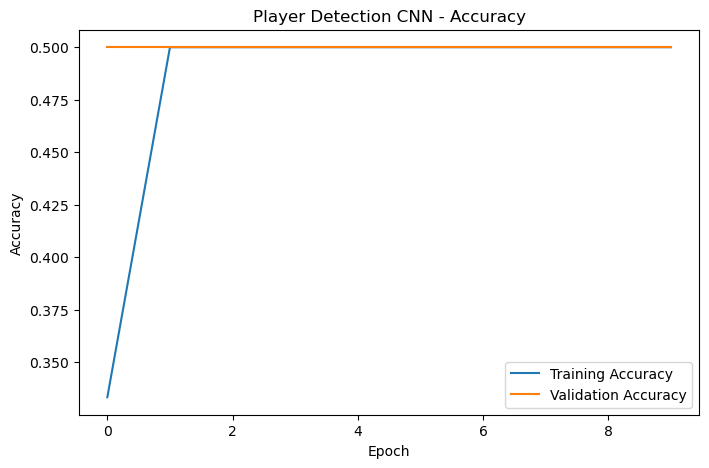

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Player Detection CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

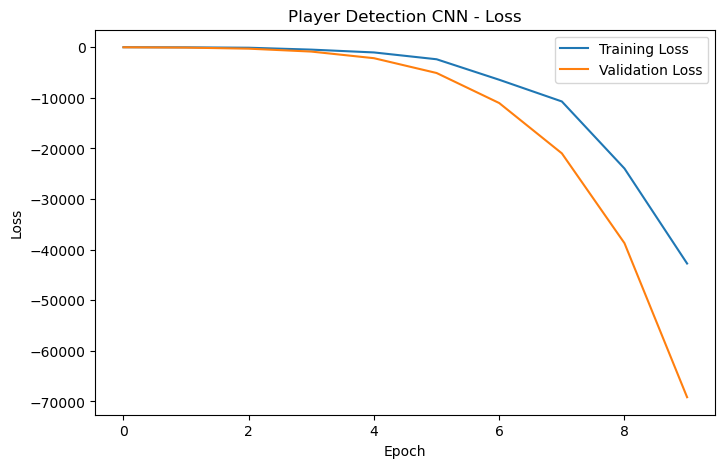

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Player Detection CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [29]:
player_detection_model.save(
    "models/player_detection.h5"
)

print("Player Detection CNN saved successfully!")

Player Detection CNN saved successfully!


In [30]:
print(os.listdir("models"))

['player_detection.h5']


In [31]:
activities = [
    "running",
    "walking",
    "shooting",
    "passing",
    "standing"
]

for activity in activities:
    os.makedirs(f"images/activity/{activity}", exist_ok=True)

print("Activity folders created successfully!")

Activity folders created successfully!


In [32]:
print(os.listdir("images/activity"))

['passing', 'running', 'shooting', 'standing', 'walking']


In [34]:
activity_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

activity_train = activity_datagen.flow_from_directory(
    "images/activity",
    target_size=(128, 128),
    batch_size=4,
    class_mode="categorical",
    subset="training"
)

activity_validation = activity_datagen.flow_from_directory(
    "images/activity",
    target_size=(128, 128),
    batch_size=4,
    class_mode="categorical",
    subset="validation"
)

Found 20 images belonging to 5 classes.
Found 5 images belonging to 5 classes.


In [35]:
print("Activity Classes:")
print(activity_train.class_indices)

Activity Classes:
{'passing': 0, 'running': 1, 'shooting': 2, 'standing': 3, 'walking': 4}


In [36]:
print("Training images:", activity_train.samples)
print("Validation images:", activity_validation.samples)
print("Number of classes:", activity_train.num_classes)

Training images: 20
Validation images: 5
Number of classes: 5


In [37]:
activity_model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=(128, 128, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation="relu"),
    Dense(5, activation="softmax")
])

activity_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
activity_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Activity CNN compiled successfully!")

Activity CNN compiled successfully!


In [39]:
activity_history = activity_model.fit(
    activity_train,
    validation_data=activity_validation,
    epochs=10
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 511ms/step - accuracy: 0.1500 - loss: 1.9984 - val_accuracy: 0.2000 - val_loss: 1.6160
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 223ms/step - accuracy: 0.1500 - loss: 1.5884 - val_accuracy: 0.6000 - val_loss: 1.5680
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 225ms/step - accuracy: 0.4000 - loss: 1.4710 - val_accuracy: 0.6000 - val_loss: 1.4877
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 201ms/step - accuracy: 0.7500 - loss: 1.1990 - val_accuracy: 0.6000 - val_loss: 1.3328
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 256ms/step - accuracy: 0.9000 - loss: 0.6975 - val_accuracy: 0.6000 - val_loss: 1.0969
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 232ms/step - accuracy: 1.0000 - loss: 0.1615 - val_accuracy: 0.4000 - val_loss: 2.5625
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step - accuracy: 0.9500 - loss: 0.4964 - val_accuracy: 0.6000 - val_loss: 1.6206
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 201ms/step - accuracy: 1.0000 - loss: 0.1272 - val_accuracy: 0.4000 - val_loss:

In [40]:
activity_model.save("models/activity_model.h5")

print("Activity Recognition CNN saved successfully!")

Activity Recognition CNN saved successfully!


In [41]:
performance_data = pd.read_csv(
    "datasets/performance_data.csv"
)

performance_data.head()

,player_id,speed,goals,assists,pass_accuracy,stamina,shots,tackles,performance_score
0,1,20,7,9,95,60,2,4,143.3
1,2,31,2,4,95,73,5,11,127.0
2,3,23,6,6,85,61,10,11,147.5
3,4,27,2,9,86,87,4,2,130.0
4,5,24,6,1,64,89,9,5,119.3


In [42]:
performance_data = pd.read_csv(
    "datasets/performance_data.csv"
)

performance_data.head()

,player_id,speed,goals,assists,pass_accuracy,stamina,shots,tackles,performance_score
0,1,20,7,9,95,60,2,4,143.3
1,2,31,2,4,95,73,5,11,127.0
2,3,23,6,6,85,61,10,11,147.5
3,4,27,2,9,86,87,4,2,130.0
4,5,24,6,1,64,89,9,5,119.3


In [43]:
X = performance_data[
    [
        "speed",
        "goals",
        "assists",
        "pass_accuracy",
        "stamina",
        "shots",
        "tackles"
    ]
]

y = performance_data["performance_score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100, 7)
Target shape: (100,)


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


In [45]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [46]:
performance_model = Sequential([
    Dense(64, activation="relu", input_shape=(7,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

performance_model.summary()

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
performance_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("Performance ANN compiled successfully!")

Performance ANN compiled successfully!


In [48]:
performance_history = performance_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=50,
    batch_size=8,
    verbose=1
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 17317.1211 - mae: 129.8591 - val_loss: 17886.7852 - val_mae: 132.5269
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 17206.6348 - mae: 129.4379 - val_loss: 17756.9883 - val_mae: 132.0439
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 17061.9277 - mae: 128.8820 - val_loss: 17579.0898 - val_mae: 131.3775
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 16860.4883 - mae: 128.1131 - val_loss: 17322.5176 - val_mae: 130.4082
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 16563.0098 - mae: 126.9607 - val_loss: 16937.4941 - val_mae: 128.9422
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 16119.0312 - mae: 125.2367 - val_loss: 16359.8906 - val_mae: 126.7139
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 15457.5342 - mae: 122.6570 - val_loss: 15533.3184 - val_mae: 123.4609
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 14537.7832 - mae: 118.9082 - val_loss:

In [49]:
test_loss, test_mae = performance_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test MAE:", test_mae)

Test Loss: 272.670654296875
Test MAE: 13.097700119018555


In [50]:
performance_model.save(
    "models/performance_model.h5"
)

print("Performance ANN saved successfully!")

Performance ANN saved successfully!


In [51]:
sample_player = pd.DataFrame({
    "speed": [30],
    "goals": [5],
    "assists": [4],
    "pass_accuracy": [85],
    "stamina": [90],
    "shots": [8],
    "tackles": [6]
})

sample_player

,speed,goals,assists,pass_accuracy,stamina,shots,tackles
0,30,5,4,85,90,8,6


In [52]:
sample_scaled = scaler.transform(sample_player)

print("Sample player scaled successfully!")

Sample player scaled successfully!


In [53]:
prediction = performance_model.predict(sample_scaled)

print("Predicted Performance Score:",
      round(float(prediction[0][0]), 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
Predicted Performance Score: 104.71


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


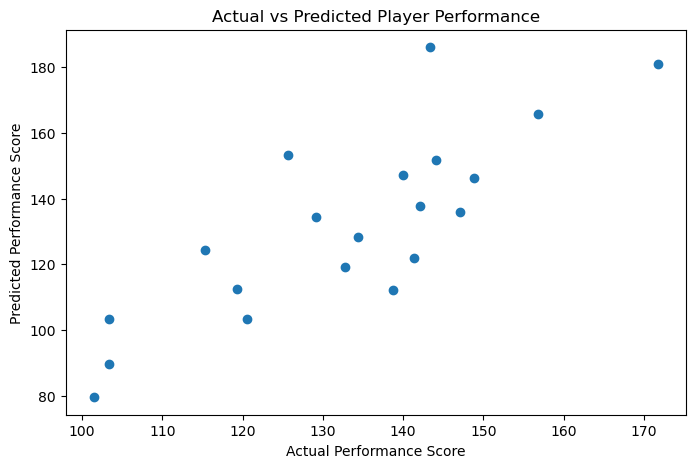

In [54]:
y_pred = performance_model.predict(X_test_scaled).flatten()

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Performance Score")
plt.ylabel("Predicted Performance Score")
plt.title("Actual vs Predicted Player Performance")

plt.show()

In [55]:
match_data = pd.read_csv("datasets/match_data.csv")

match_data.head()

,match_id,team_a_score,team_b_score,team_a_possession,team_b_possession,team_a_shots,team_b_shots,team_a_ranking,team_b_ranking,result
0,1,3,0,56,54,6,3,16,7,1
1,2,0,1,51,45,14,10,13,17,0
2,3,3,3,56,50,14,14,9,10,2
3,4,0,1,49,52,6,10,13,10,0
4,5,1,0,40,40,14,14,9,4,1


In [56]:
X_match = match_data[
    [
        "team_a_score",
        "team_b_score",
        "team_a_possession",
        "team_b_possession",
        "team_a_shots",
        "team_b_shots",
        "team_a_ranking",
        "team_b_ranking"
    ]
]

y_match = match_data["result"]

print("Features shape:", X_match.shape)
print("Target shape:", y_match.shape)

Features shape: (100, 8)
Target shape: (100,)


In [57]:
X_match_train, X_match_test, y_match_train, y_match_test = train_test_split(
    X_match,
    y_match,
    test_size=0.2,
    random_state=42,
    stratify=y_match
)

print("Training samples:", len(X_match_train))
print("Testing samples:", len(X_match_test))

Training samples: 80
Testing samples: 20


In [58]:
match_scaler = StandardScaler()

X_match_train_scaled = match_scaler.fit_transform(X_match_train)
X_match_test_scaled = match_scaler.transform(X_match_test)

print("Match data scaling completed!")

Match data scaling completed!


In [59]:
match_model = Sequential([
    Dense(64, activation="relu", input_shape=(8,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(3, activation="softmax")
])

match_model.summary()

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,235 (12.64 KB)

 Trainable params: 3,235 (12.64 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
match_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Match Outcome ANN compiled successfully!")

Match Outcome ANN compiled successfully!


In [61]:
match_history = match_model.fit(
    X_match_train_scaled,
    y_match_train,
    validation_data=(X_match_test_scaled, y_match_test),
    epochs=50,
    batch_size=8,
    verbose=1
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.2875 - loss: 1.1167 - val_accuracy: 0.5500 - val_loss: 1.0831
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5125 - loss: 1.0697 - val_accuracy: 0.5500 - val_loss: 1.0665
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6000 - loss: 1.0383 - val_accuracy: 0.4500 - val_loss: 1.0495
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6750 - loss: 1.0042 - val_accuracy: 0.6000 - val_loss: 1.0321
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7250 - loss: 0.9599 - val_accuracy: 0.7500 - val_loss: 1.0026
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7375 - loss: 0.9092 - val_accuracy: 0.8000 - val_loss: 0.9642
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7500 - loss: 0.8413 - val_accuracy: 0.8000 - val_loss: 0.9109
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7750 - loss: 0.7666 - val_accuracy: 0.8000 - v

In [62]:
match_loss, match_accuracy = match_model.evaluate(
    X_match_test_scaled,
    y_match_test,
    verbose=0
)

print("Test Loss:", match_loss)
print("Test Accuracy:", match_accuracy)

Test Loss: 0.18829497694969177
Test Accuracy: 0.8999999761581421


In [63]:
match_model.save("models/match_model.h5")

print("Match Outcome ANN saved successfully!")

Match Outcome ANN saved successfully!


In [64]:
sample_match = pd.DataFrame({
    "team_a_score": [2],
    "team_b_score": [1],
    "team_a_possession": [55],
    "team_b_possession": [45],
    "team_a_shots": [10],
    "team_b_shots": [7],
    "team_a_ranking": [5],
    "team_b_ranking": [12]
})

sample_match

,team_a_score,team_b_score,team_a_possession,team_b_possession,team_a_shots,team_b_shots,team_a_ranking,team_b_ranking
0,2,1,55,45,10,7,5,12


In [65]:
sample_match_scaled = match_scaler.transform(sample_match)

print("Sample match scaled successfully!")

Sample match scaled successfully!


In [66]:
prediction = match_model.predict(sample_match_scaled)

predicted_class = np.argmax(prediction[0])

result_names = {
    0: "Team B Wins",
    1: "Team A Wins",
    2: "Draw"
}

print("Prediction Probabilities:", prediction[0])
print("Predicted Match Outcome:", result_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
Prediction Probabilities: [0.00187012 0.9568182  0.04131164]
Predicted Match Outcome: Team A Wins


In [67]:
performance_scores = performance_data["performance_score"].values

print("Total performance records:", len(performance_scores))

Total performance records: 100


In [68]:
from sklearn.preprocessing import MinMaxScaler

lstm_scaler = MinMaxScaler()

scaled_scores = lstm_scaler.fit_transform(
    performance_scores.reshape(-1, 1)
)

print("Performance data normalized successfully!")

Performance data normalized successfully!


In [69]:
sequence_length = 10

X_lstm = []
y_lstm = []

for i in range(sequence_length, len(scaled_scores)):
    X_lstm.append(
        scaled_scores[i-sequence_length:i]
    )
    y_lstm.append(
        scaled_scores[i]
    )

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)

print("X shape:", X_lstm.shape)
print("y shape:", y_lstm.shape)

X shape: (90, 10, 1)
y shape: (90, 1)


In [70]:
split = int(len(X_lstm) * 0.8)

X_lstm_train = X_lstm[:split]
X_lstm_test = X_lstm[split:]

y_lstm_train = y_lstm[:split]
y_lstm_test = y_lstm[split:]

print("Training sequences:", len(X_lstm_train))
print("Testing sequences:", len(X_lstm_test))

Training sequences: 72
Testing sequences: 18


In [71]:
lstm_model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(10, 1)
    ),

    LSTM(32),

    Dense(16, activation="relu"),

    Dense(1)
])

lstm_model.summary()

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

print("LSTM model compiled successfully!")

LSTM model compiled successfully!


In [73]:
lstm_history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    validation_data=(X_lstm_test, y_lstm_test),
    epochs=50,
    batch_size=8,
    verbose=1
)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 153ms/step - loss: 0.1189 - mae: 0.2839 - val_loss: 0.0731 - val_mae: 0.2169
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0630 - mae: 0.1953 - val_loss: 0.0677 - val_mae: 0.2044
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0493 - mae: 0.1801 - val_loss: 0.0644 - val_mae: 0.1961
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0516 - mae: 0.1860 - val_loss: 0.0666 - val_mae: 0.2008
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0497 - mae: 0.1758 - val_loss: 0.0715 - val_mae: 0.2135
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0502 - mae: 0.1796 - val_loss: 0.0655 - val_mae: 0.1984
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0503 - mae: 0.1787 - val_loss: 0.0685 - val_mae: 0.2068
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0502 - mae: 0.1795 - val_loss: 0.0653 - val_mae: 0.1981
Epoch 9/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0489 - mae: 0.1780 -

In [74]:
lstm_loss, lstm_mae = lstm_model.evaluate(
    X_lstm_test,
    y_lstm_test,
    verbose=0
)

print("LSTM Test Loss:", lstm_loss)
print("LSTM Test MAE:", lstm_mae)

LSTM Test Loss: 0.06415597349405289
LSTM Test MAE: 0.1986408233642578


In [75]:
lstm_model.save("models/lstm_model.h5")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [76]:
lstm_predictions = lstm_model.predict(X_lstm_test)

print("Predictions generated successfully!")
print("Prediction shape:", lstm_predictions.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 644ms/step
Predictions generated successfully!
Prediction shape: (18, 1)


In [77]:
actual_scores = lstm_scaler.inverse_transform(y_lstm_test)
predicted_scores = lstm_scaler.inverse_transform(lstm_predictions)

print("Actual Scores:")
print(actual_scores[:5].flatten())

print("\nPredicted Scores:")
print(predicted_scores[:5].flatten())

Actual Scores:
[148.9 115.3 131.3 125.1 153.6]

Predicted Scores:
[130.80212 130.29048 130.22449 130.05765 129.78746]


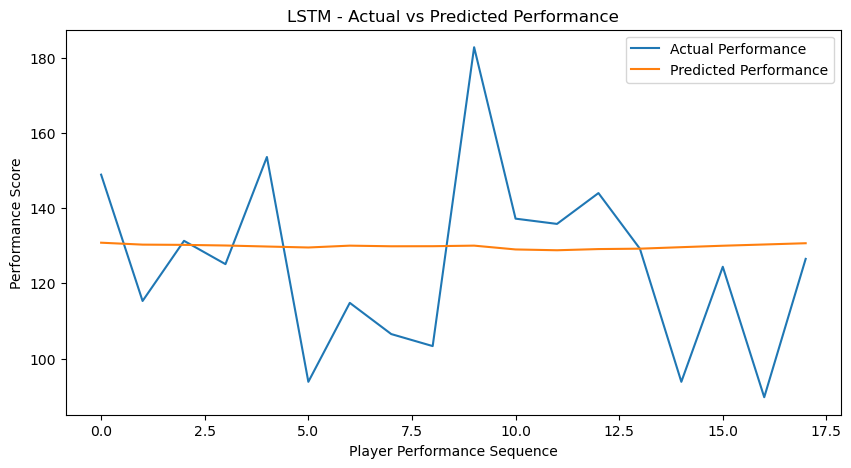

In [78]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual_scores.flatten(),
    label="Actual Performance"
)

plt.plot(
    predicted_scores.flatten(),
    label="Predicted Performance"
)

plt.title("LSTM - Actual vs Predicted Performance")
plt.xlabel("Player Performance Sequence")
plt.ylabel("Performance Score")
plt.legend()

plt.show()

In [79]:
last_sequence = scaled_scores[-sequence_length:]

last_sequence = last_sequence.reshape(
    1,
    sequence_length,
    1
)

next_prediction = lstm_model.predict(last_sequence)

next_score = lstm_scaler.inverse_transform(
    next_prediction
)

print(
    "Predicted Next Performance Score:",
    round(float(next_score[0][0]), 2)
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 804ms/step
Predicted Next Performance Score: 130.38


In [80]:
print("DATASETS:")
print(os.listdir("datasets"))

DATASETS:
['match_data.csv', 'performance_data.csv', 'player_data.csv']


In [81]:
print("MODELS:")
print(os.listdir("models"))

MODELS:
['.ipynb_checkpoints', 'activity_model.h5', 'lstm_model.h5', 'match_model.h5', 'performance_model.h5', 'player_detection.h5']


In [82]:
print("IMAGES:")
print(os.listdir("images"))

IMAGES:
['.ipynb_checkpoints', 'activity', 'non_player', 'player']


In [83]:
print("=" * 60)
print("🏆 AI-POWERED SPORTS ANALYTICS & PERFORMANCE PLATFORM")
print("=" * 60)

print("\n📌 AI MODULES")
print("-" * 60)

print("1. Player Detection              → CNN ✅")
print("2. Player Activity Recognition   → CNN ✅")
print("3. Player Performance Prediction → ANN ✅")
print("4. Match Outcome Prediction      → ANN ✅")
print("5. Performance Forecasting       → LSTM ✅")

print("\n📂 DATASETS")
print("-" * 60)

print("✓ player_data.csv")
print("✓ performance_data.csv")
print("✓ match_data.csv")

print("\n🤖 TRAINED MODELS")
print("-" * 60)

print("✓ player_detection.h5")
print("✓ activity_model.h5")
print("✓ performance_model.h5")
print("✓ match_model.h5")
print("✓ lstm_model.h5")

print("\n" + "=" * 60)
print("PROJECT STATUS: COMPLETED ✅")
print("=" * 60)

🏆 AI-POWERED SPORTS ANALYTICS & PERFORMANCE PLATFORM

📌 AI MODULES
------------------------------------------------------------
1. Player Detection              → CNN ✅
2. Player Activity Recognition   → CNN ✅
3. Player Performance Prediction → ANN ✅
4. Match Outcome Prediction      → ANN ✅
5. Performance Forecasting       → LSTM ✅

📂 DATASETS
------------------------------------------------------------
✓ player_data.csv
✓ performance_data.csv
✓ match_data.csv

🤖 TRAINED MODELS
------------------------------------------------------------
✓ player_detection.h5
✓ activity_model.h5
✓ performance_model.h5
✓ match_model.h5
✓ lstm_model.h5

PROJECT STATUS: COMPLETED ✅


In [84]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [85]:
from IPython.display import Markdown, display

display(Markdown("""
# 🏆 AI Sports Analytics Dashboard

### AI-Powered Sports Performance & Match Analysis

**Available Predictions**
- 🧠 Player Performance
- ⚽ Match Outcome
- 📈 Future Performance Forecast
"""))


# 🏆 AI Sports Analytics Dashboard

### AI-Powered Sports Performance & Match Analysis

**Available Predictions**
- 🧠 Player Performance
- ⚽ Match Outcome
- 📈 Future Performance Forecast


In [86]:
def predict_player_performance(
    speed,
    goals,
    assists,
    pass_accuracy,
    stamina,
    shots,
    tackles
):
    player = pd.DataFrame({
        "speed": [speed],
        "goals": [goals],
        "assists": [assists],
        "pass_accuracy": [pass_accuracy],
        "stamina": [stamina],
        "shots": [shots],
        "tackles": [tackles]
    })

    player_scaled = scaler.transform(player)

    prediction = performance_model.predict(
        player_scaled,
        verbose=0
    )

    print(
        "🏆 Predicted Performance Score:",
        round(float(prediction[0][0]), 2)
    )

In [87]:
speed_input = widgets.IntSlider(
    value=30, min=20, max=35, description="Speed:"
)

goals_input = widgets.IntSlider(
    value=5, min=0, max=9, description="Goals:"
)

assists_input = widgets.IntSlider(
    value=4, min=0, max=9, description="Assists:"
)

pass_input = widgets.IntSlider(
    value=85, min=60, max=100, description="Pass %:"
)

stamina_input = widgets.IntSlider(
    value=85, min=60, max=100, description="Stamina:"
)

shots_input = widgets.IntSlider(
    value=8, min=1, max=14, description="Shots:"
)

tackles_input = widgets.IntSlider(
    value=6, min=0, max=11, description="Tackles:"
)

predict_button = widgets.Button(
    description="Predict Performance"
)

output = widgets.Output()

In [88]:
def on_predict_clicked(button):
    with output:
        clear_output()

        predict_player_performance(
            speed_input.value,
            goals_input.value,
            assists_input.value,
            pass_input.value,
            stamina_input.value,
            shots_input.value,
            tackles_input.value
        )

predict_button.on_click(on_predict_clicked)

display(
    speed_input,
    goals_input,
    assists_input,
    pass_input,
    stamina_input,
    shots_input,
    tackles_input,
    predict_button,
    output
)

IntSlider(value=30, description='Speed:', max=35, min=20)

IntSlider(value=5, description='Goals:', max=9)

IntSlider(value=4, description='Assists:', max=9)

IntSlider(value=85, description='Pass %:', min=60)

IntSlider(value=85, description='Stamina:', min=60)

IntSlider(value=8, description='Shots:', max=14, min=1)

IntSlider(value=6, description='Tackles:', max=11)

Button(description='Predict Performance', style=ButtonStyle())

Output()

In [89]:
def predict_match_outcome(
    team_a_score,
    team_b_score,
    team_a_possession,
    team_b_possession,
    team_a_shots,
    team_b_shots,
    team_a_ranking,
    team_b_ranking
):
    match = pd.DataFrame({
        "team_a_score": [team_a_score],
        "team_b_score": [team_b_score],
        "team_a_possession": [team_a_possession],
        "team_b_possession": [team_b_possession],
        "team_a_shots": [team_a_shots],
        "team_b_shots": [team_b_shots],
        "team_a_ranking": [team_a_ranking],
        "team_b_ranking": [team_b_ranking]
    })

    match_scaled = match_scaler.transform(match)

    prediction = match_model.predict(
        match_scaled,
        verbose=0
    )

    predicted_class = np.argmax(prediction[0])

    result_names = {
        0: "Team B Wins 🟢",
        1: "Team A Wins 🔵",
        2: "Draw 🟡"
    }

    print("⚽ Predicted Outcome:", result_names[predicted_class])
    print("📊 Probabilities:")

    for i, label in enumerate(result_names.values()):
        print(f"{label}: {prediction[0][i] * 100:.2f}%")

In [90]:
team_a_score = widgets.IntSlider(
    value=2, min=0, max=5, description="Team A Score:"
)

team_b_score = widgets.IntSlider(
    value=1, min=0, max=5, description="Team B Score:"
)

team_a_possession = widgets.IntSlider(
    value=55, min=40, max=60, description="Team A Poss.:"
)

team_b_possession = widgets.IntSlider(
    value=45, min=40, max=60, description="Team B Poss.:"
)

team_a_shots = widgets.IntSlider(
    value=10, min=3, max=15, description="Team A Shots:"
)

team_b_shots = widgets.IntSlider(
    value=7, min=3, max=15, description="Team B Shots:"
)

team_a_ranking = widgets.IntSlider(
    value=5, min=1, max=20, description="Team A Rank:"
)

team_b_ranking = widgets.IntSlider(
    value=12, min=1, max=20, description="Team B Rank:"
)

match_button = widgets.Button(
    description="Predict Match"
)

match_output = widgets.Output()

In [91]:
def on_match_predict(button):
    with match_output:
        clear_output()

        predict_match_outcome(
            team_a_score.value,
            team_b_score.value,
            team_a_possession.value,
            team_b_possession.value,
            team_a_shots.value,
            team_b_shots.value,
            team_a_ranking.value,
            team_b_ranking.value
        )

match_button.on_click(on_match_predict)

display(
    team_a_score,
    team_b_score,
    team_a_possession,
    team_b_possession,
    team_a_shots,
    team_b_shots,
    team_a_ranking,
    team_b_ranking,
    match_button,
    match_output
)

IntSlider(value=2, description='Team A Score:', max=5)

IntSlider(value=1, description='Team B Score:', max=5)

IntSlider(value=55, description='Team A Poss.:', max=60, min=40)

IntSlider(value=45, description='Team B Poss.:', max=60, min=40)

IntSlider(value=10, description='Team A Shots:', max=15, min=3)

IntSlider(value=7, description='Team B Shots:', max=15, min=3)

IntSlider(value=5, description='Team A Rank:', max=20, min=1)

IntSlider(value=12, description='Team B Rank:', max=20, min=1)

Button(description='Predict Match', style=ButtonStyle())

Output()

In [92]:
def predict_future_performance():
    last_sequence = scaled_scores[-sequence_length:]

    last_sequence = last_sequence.reshape(
        1,
        sequence_length,
        1
    )

    prediction = lstm_model.predict(
        last_sequence,
        verbose=0
    )

    predicted_score = lstm_scaler.inverse_transform(
        prediction
    )

    print(
        "📈 Predicted Next Performance Score:",
        round(float(predicted_score[0][0]), 2)
    )

In [93]:
forecast_button = widgets.Button(
    description="Forecast Next Performance"
)

forecast_output = widgets.Output()

In [94]:
def on_forecast_clicked(button):
    with forecast_output:
        clear_output()

        predict_future_performance()

forecast_button.on_click(on_forecast_clicked)

display(
    forecast_button,
    forecast_output
)

Button(description='Forecast Next Performance', style=ButtonStyle())

Output()

In [95]:
from tensorflow.keras.utils import load_img, img_to_array

# Activity class mapping
activity_classes = {
    v: k for k, v in activity_train.class_indices.items()
}

print("Activity Classes:", activity_classes)

Activity Classes: {0: 'passing', 1: 'running', 2: 'shooting', 3: 'standing', 4: 'walking'}


In [96]:
def predict_activity(image_path):

    # Load image
    img = load_img(
        image_path,
        target_size=(128, 128)
    )

    # Convert image to array
    img_array = img_to_array(img)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = activity_model.predict(
        img_array,
        verbose=0
    )[0]

    # Get predicted class
    predicted_index = np.argmax(prediction)

    predicted_activity = activity_classes[predicted_index]

    confidence = prediction[predicted_index] * 100

    print("🏃 Predicted Activity:", predicted_activity.upper())
    print("🎯 Confidence:", round(float(confidence), 2), "%")

In [97]:
activity_files = []

for activity in activities:
    folder = os.path.join("images/activity", activity)

    for file in os.listdir(folder):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            activity_files.append(
                os.path.join(folder, file)
            )

print("Total Activity Images:", len(activity_files))

Total Activity Images: 25


In [98]:
activity_dropdown = widgets.Dropdown(
    options=activity_files,
    description="Select Image:",
    layout=widgets.Layout(width="600px")
)

activity_button = widgets.Button(
    description="Predict Activity"
)

activity_output = widgets.Output()

In [99]:
def on_activity_predict(button):

    with activity_output:
        clear_output()

        selected_image = activity_dropdown.value

        print("🖼️ Selected Image:")
        print(selected_image)
        print()

        predict_activity(selected_image)


activity_button.on_click(on_activity_predict)

display(
    activity_dropdown,
    activity_button,
    activity_output
)

Dropdown(description='Select Image:', layout=Layout(width='600px'), options=('images/activity\\running\\WhatsA…

Button(description='Predict Activity', style=ButtonStyle())

Output()

In [ ]:
print("=" * 60)
print("🏆 AI SPORTS ANALYTICS PLATFORM")
print("=" * 60)

print("\n🤖 AI MODULES")
print("-" * 60)

print("1. Player Detection              → CNN ✅")
print("2. Player Activity Recognition   → CNN ✅")
print("3. Player Performance Prediction → ANN ✅")
print("4. Match Outcome Prediction      → ANN ✅")
print("5. Performance Forecasting       → LSTM ✅")

print("\n📂 DATASETS")
print("-" * 60)

for file in os.listdir("datasets"):
    print("✓", file)

print("\n🤖 TRAINED MODELS")
print("-" * 60)

for file in os.listdir("models"):
    if file.endswith(".h5"):
        print("✓", file)

print("\n" + "=" * 60)
print("PROJECT STATUS: COMPLETED ✅")
print("=" * 60)